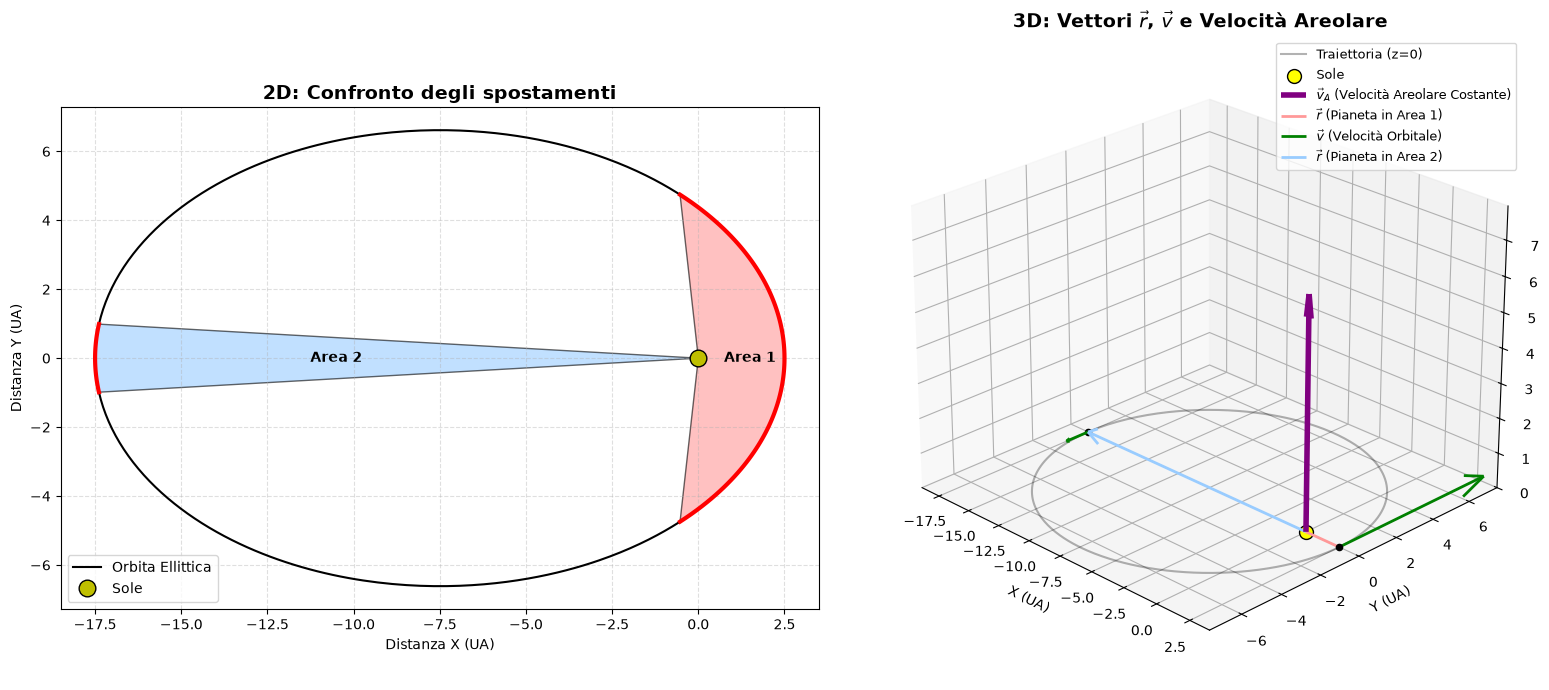

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon

# --- 1. Configurazione del grafico (1 riga, 2 colonne) ---
fig = plt.figure(figsize=(16, 7))

# ==========================================
# SUBPLOT 1: 2D (Aree e Spostamento)
# ==========================================
ax1 = fig.add_subplot(1, 2, 1)
ax1.set_aspect('equal')
ax1.set_title("2D: Confronto degli spostamenti", fontsize=14, fontweight='bold')
ax1.set_xlabel("Distanza X (UA)")
ax1.set_ylabel("Distanza Y (UA)")
ax1.grid(True, linestyle='--', alpha=0.4)

eccentricity = 0.75  
semi_major_axis = 10.0 
sun_position = (0, 0)
p = semi_major_axis * (1 - eccentricity**2)

true_anomalies = np.linspace(0, 2 * np.pi, 500)
distances = p / (1 + eccentricity * np.cos(true_anomalies))
x_orbit = distances * np.cos(true_anomalies)
y_orbit = distances * np.sin(true_anomalies)

ax1.plot(x_orbit, y_orbit, 'k-', linewidth=1.5, label='Orbita Ellittica')
ax1.plot(sun_position[0], sun_position[1], 'yo', markersize=12, markeredgecolor='black', label='Sole')

delta_M = np.pi / 6  
settori_M = [(-delta_M / 2, delta_M / 2), (np.pi - delta_M / 2, np.pi + delta_M / 2)]
colori = ['#ff9999', '#99ccff']
etichette = ['Area 1', 'Area 2']

def mean_to_true_anomaly(M, e):
    E = M
    for _ in range(15): 
        E = E - (E - e * np.sin(E) - M) / (1 - e * np.cos(E))
    return 2 * np.arctan2(np.sqrt(1 + e) * np.sin(E / 2), np.sqrt(1 - e) * np.cos(E / 2))

for i, (start_M, end_M) in enumerate(settori_M):
    nu_start = mean_to_true_anomaly(start_M, eccentricity)
    nu_end = mean_to_true_anomaly(end_M, eccentricity)
    if nu_end < nu_start: nu_end += 2 * np.pi
        
    arc_ta = np.linspace(nu_start, nu_end, 100)
    arc_dist = p / (1 + eccentricity * np.cos(arc_ta))
    x_arc, y_arc = arc_dist * np.cos(arc_ta), arc_dist * np.sin(arc_ta)
    
    ax1.plot(x_arc, y_arc, color='red', linewidth=3, zorder=5)
    poly = Polygon(np.vstack(((0, 0), np.column_stack((x_arc, y_arc)))), closed=True, facecolor=colori[i], edgecolor='black', alpha=0.6)
    ax1.add_patch(poly)
    
    nu_mid = mean_to_true_anomaly((start_M + end_M) / 2, eccentricity)
    dist_mid = p / (1 + eccentricity * np.cos(nu_mid))
    ax1.text((dist_mid * 0.6) * np.cos(nu_mid), (dist_mid * 0.6) * np.sin(nu_mid), etichette[i], ha='center', va='center', fontsize=10, fontweight='bold')

ax1.legend(loc='lower left')

# ==========================================
# SUBPLOT 2: 3D (Traiettoria e Vettori)
# ==========================================
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.set_title("3D: Vettori $\\vec{r}$, $\\vec{v}$ e Velocità Areolare", fontsize=14, fontweight='bold')
ax2.set_xlabel("X (UA)")
ax2.set_ylabel("Y (UA)")
ax2.set_zlabel("Z")

# Plot dell'orbita sul piano Z=0
ax2.plot(x_orbit, y_orbit, np.zeros_like(x_orbit), 'k-', alpha=0.3, label='Traiettoria (z=0)')
ax2.scatter(*sun_position, 0, color='yellow', s=100, edgecolor='black', label='Sole')

# Parametro gravitazionale (scalato arbitrariamente per la visualizzazione dei vettori)
mu = 40.0 

# La velocità areolare è v_A = 1/2 * (r x v). La sua magnitudo per un'ellisse è costante: 1/2 * sqrt(mu * p)
v_A_mag = 0.5 * np.sqrt(mu * p)

# Disegniamo il vettore Velocità Areolare (costante, lo posizioniamo nell'origine)
ax2.quiver(0, 0, 0, 0, 0, v_A_mag, color='purple', linewidth=4, arrow_length_ratio=0.1, label='$\\vec{v}_A$ (Velocità Areolare Costante)')

scale_v = 1.5 # Fattore di scala per allungare visivamente il vettore velocità

# Calcoliamo e tracciamo i vettori r e v nei due punti medi dei settori
for i, (start_M, end_M) in enumerate(settori_M):
    mid_M = (start_M + end_M) / 2
    nu = mean_to_true_anomaly(mid_M, eccentricity)
    
    # 1. Vettore Posizione (r)
    r_mag = p / (1 + eccentricity * np.cos(nu))
    rx, ry = r_mag * np.cos(nu), r_mag * np.sin(nu)
    
    # 2. Vettore Velocità (v) - componenti cartesiane dall'orbita polare
    vx = -np.sqrt(mu/p) * np.sin(nu)
    vy = np.sqrt(mu/p) * (eccentricity + np.cos(nu))
    
    # Disegno Vettore r (dal Sole al pianeta)
    ax2.quiver(0, 0, 0, rx, ry, 0, color=colori[i], arrow_length_ratio=0.05, linewidth=2, label=f'$\\vec{{r}}$ (Pianeta in Area {i+1})')
    
    # Disegno Vettore v (dal pianeta, tangente all'orbita)
    lbl_v = '$\\vec{v}$ (Velocità Orbitale)' if i == 0 else ""
    ax2.quiver(rx, ry, 0, vx * scale_v, vy * scale_v, 0, color='green', arrow_length_ratio=0.15, linewidth=2, label=lbl_v)
    
    # Punto che rappresenta il pianeta
    ax2.scatter(rx, ry, 0, color='black', s=20)

# Impostazioni visuali del grafico 3D
ax2.set_zlim(0, v_A_mag * 1.2)
ax2.view_init(elev=25, azim=-45) # Angolazione per vedere bene i vettori
ax2.legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig("../Appunti/img/kepler_second_law_2D_3D.png", dpi=800) 
plt.show()